# Synergy 1 — does “beating the odds together” work?

This is an executed, offline experiment, not a change to the app. No users,
groups, credentials, or databases are read. The existing simulation notebook
and SQLite database are not used or modified.

**Design brief:** one shared signed score per partnership; zero means as
expected, positive means above expectations. Surprise wins matter most, score
margins also matter, recent pair games count more, and raw win rate is context
rather than the ranking driver. User context: around 1.5 games together per
session. The existing app uses Laplace-smoothed win rate for synergy.

**Main result:** an expected-20%, actual-40% pair can outrank an expected-85%,
actual-85% pair. But noisy “best partner” selection and baseline-rating errors
are substantial; see Notebook 2 before interpreting a score.

All tabulated means and intervals below describe repeated synthetic histories,
not evidence about real players. 5th–95th percentiles are the spread across
histories, **not confidence intervals on the displayed mean**.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sys
BASE = Path.cwd() if Path("synergy_simulation.py").exists() else Path.cwd() / "analysis"
if not (BASE / "synergy_simulation.py").exists():
    raise FileNotFoundError("Start this notebook from the repository root or analysis directory.")
sys.path.insert(0, str(BASE.resolve()))
from synergy_simulation import ScoreModel, contributions, estimate, weights, evidence
OUT = BASE / "synergy_results"
manifest = json.loads((OUT / "manifest.json").read_text())
def load(name):
    return pd.read_csv(OUT / f"{name}.csv", keep_default_na=False)
def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=170, bbox_inches="tight")
    svg = OUT / f"{name}.svg"
    fig.savefig(svg, bbox_inches="tight", metadata={"Date": None})
    svg.write_text(chr(10).join(line.rstrip() for line in svg.read_text().splitlines()) + chr(10))
    plt.show()
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                    "axes.spines.right": False, "axes.grid": True, "grid.alpha": .18,
                    "font.size": 11, "figure.facecolor": "white", "svg.hashsalt": "synergy-20261015"})
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
model = ScoreModel()
print(f"Seed {manifest['seed']}; independent follow-up seed {manifest['holdout_seed']}")
print(f"{manifest['synthetic_matches']:,} synthetic matches; {manifest['repetitions']:,} histories per main cell")
print("Invariant checks:", manifest["checks"])


Seed 20261015; independent follow-up seed 20261016
10,964,000 synthetic matches; 4,000 histories per main cell
Invariant checks: {'probability_mass': True, 'neutral_center': True, 'team_reversal_symmetry': True, 'neutral_history_score': True, 'finite_recency_information': True}


## 1. A transparent candidate formula

For completed doubles game `i`, before any post-match rating update:

- `p_i = 1 / (1 + 10 ** ((opponent_mean_rating - own_mean_rating) / 400))`.
  This matches `src/lib/matchmaking/rating.ts`.
- Result residual `r_i = win_i - p_i`.
- Normalized margin `m_i = (own_points - opponent_points) / total_points`.
- Margin residual `d_i = c * (m_i - expected_margin(p_i))`.
- Contribution `x_i = alpha * r_i + (1-alpha) * d_i`.
- Pair-game-age weights `w_i = 2 ** (-age_i / half_life)`.
- Evidence diagnostic `n_eff = sum(w)**2 / sum(w**2)`.
- Signed index `S = 100 * weighted_mean(x) * n_eff / (n_eff + prior)`.

`c` matches the per-game standard deviation of margin to the binary residual at
50/50 strength. This makes blend weights comparable around equal strength,
not at every possible probability. No clipping is used, because clipping can
shift the neutral expectation. The index is **not a percentage, probability,
or a promised [-100,100] scale**. The `prior` is a conservative heuristic,
not a fitted Bayesian posterior. Missing scores and invalid/tied games are
outside this generator; a production pipeline would need explicit policies.

For the initial benchmark: alpha 0.7, half-life 6, prior 6. Other settings are
compared using the same sampled histories, so differences are not random-run
artifacts. Raw win rate does not enter the candidate index.


In [2]:
p = np.array([.2, .5, .9, .9])
wins = np.array([1, 1, 1, 0])
display(pd.DataFrame({"expected_win_probability": p, "won": wins,
                      "result_contribution": wins-p}))
print(f"Margin normalization c = {model.margin_scale:.4f}")


,expected_win_probability,won,result_contribution
0,0.200,1,0.800
1,0.500,1,0.500
2,0.900,1,0.100
3,0.900,0,-0.900


Margin normalization c = 1.8244


## 2. What does expected score margin mean?

Elo supplies a game-win probability, not an expected final score. Here we make
an explicit *experimental* bridge: independently awarded points, first to 11,
win by two. An exact terminal-score distribution is computed using
negative-binomial finish probabilities and a geometric deuce tail. We invert
its game-win curve to find a point probability for each Elo probability, then
calculate expected normalized margin from the entire score distribution.

This is **not a validated side-out pickleball model**. It omits serving,
rotation, strategic play, teammate imbalance and session effects. Its role is
to make the assumptions inspectable and falsifiable. Notebook 2 changes score
shapes and target lengths to test those assumptions.

Sampling uses a 4,001-row point-probability grid; maximum adjacent game-win
probability step is recorded below. This limits tiny numerical calibration
error, not structural model error.


Maximum game-probability grid step: 0.00093031963564566


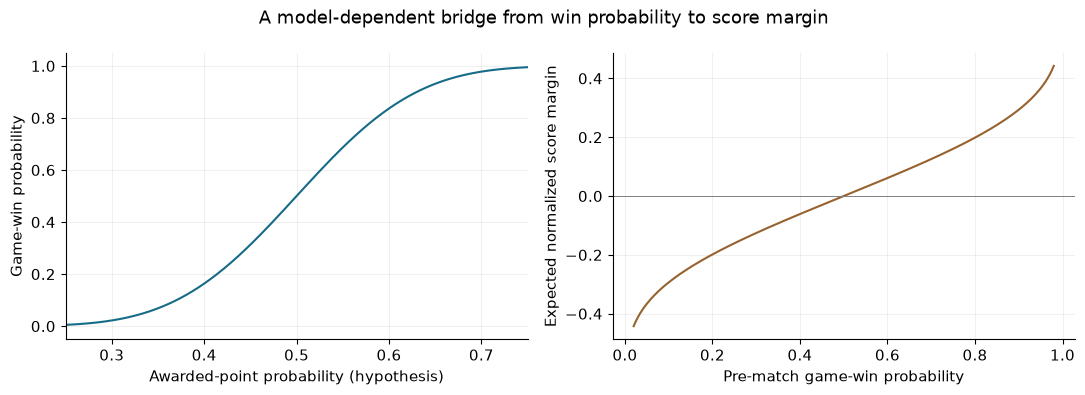

In [3]:
print("Maximum game-probability grid step:", manifest["grid_max_probability_step"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(model.q, model.p, color="#176b88")
ax[0].set(xlim=(.25,.75), xlabel="Awarded-point probability (hypothesis)", ylabel="Game-win probability")
pp=np.linspace(.02,.98,200)
ax[1].plot(pp, model.expected_margin(pp), color="#98622e")
ax[1].axhline(0,color="gray",lw=.7)
ax[1].set(xlabel="Pre-match game-win probability", ylabel="Expected normalized score margin")
fig.suptitle("A model-dependent bridge from win probability to score margin")
fig.tight_layout(); save(fig, "margin_model")


## 3. Does it express the intended partnership ranking?

Eight synthetic partnership types are repeated 4,000 times at several history
lengths. “Competitive losses” and “Blowout losses” keep the same win outcomes
and probabilities but alter only the losing side's points in losses by three,
preserving the winner and canonicalizing deuce scores to valid first-to-11,
win-by-two finishes. They deliberately test margin
behavior rather than the point model's own assumptions.


,scenario,raw_win_rate,mean,p05,p95,positive_rate
67,LeBron: expected dominance,0.850,0.100,-12.039,9.952,0.540
172,Underdogs: 20% to 40%,0.398,14.991,0.567,29.548,0.959
277,Balanced: 50% to 60%,0.604,7.609,-7.529,21.882,0.801
382,Balanced: no chemistry,0.497,-0.111,-14.886,14.303,0.501
487,Underperforming: 60% to 40%,0.398,-14.689,-29.113,-0.132,0.049
592,Underdogs: as expected,0.201,0.082,-11.325,13.329,0.475
697,Competitive losses,0.201,4.541,-5.655,16.574,0.729
802,Blowout losses,0.201,-7.860,-21.164,7.418,0.180


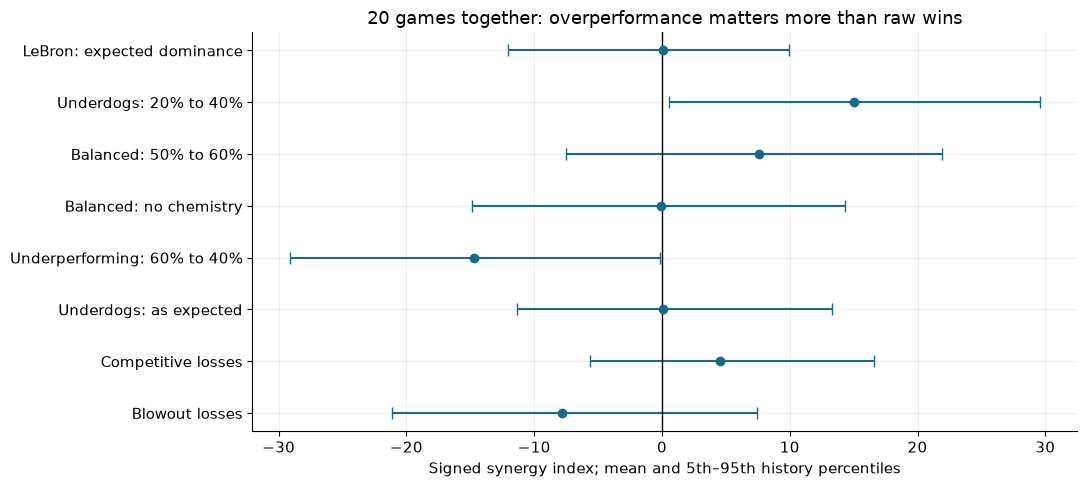

In [4]:
scoring=load("scoring")
selected=scoring.query("n == 20 and result_weight == 0.7 and prior == 6").copy()
display(selected[["scenario","raw_win_rate","mean","p05","p95","positive_rate"]])
fig,ax=plt.subplots(figsize=(11,5))
y=np.arange(len(selected))
ax.errorbar(selected["mean"],y,
            xerr=np.vstack([selected["mean"]-selected.p05,selected.p95-selected["mean"]]),
            fmt="o",capsize=4,color="#176b88")
ax.set_yticks(y,selected.scenario)
ax.axvline(0,color="black",lw=1)
ax.set(xlabel="Signed synergy index; mean and 5th–95th history percentiles",
       title="20 games together: overperformance matters more than raw wins")
ax.invert_yaxis();fig.tight_layout();save(fig,"partnership_scenarios")


The overperforming underdog has a positive mean while the expected-dominant
“LeBron” pair remains near zero. Underperforming pairs are negative. Close
losses receive more credit than blowout losses with the same win rate.

The broad intervals matter: even twenty games do not establish a stable order
between all partners. Recency weights mean twenty historical games provide
less information than twenty equally weighted independent games.


,n,result_weight,correct_synergy_rank,correct_raw_win_rate_rank
12,20,0.500,0.926,0.001
13,20,0.700,0.919,0.001
14,20,0.900,0.907,0.001
15,20,1.000,0.897,0.001


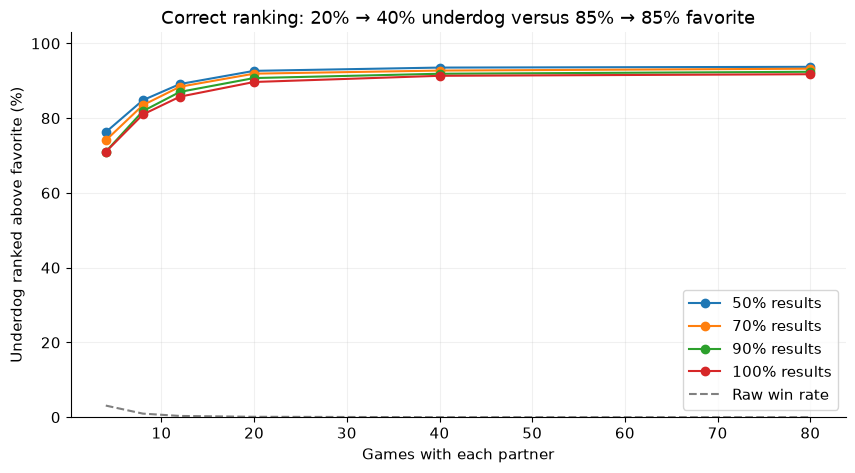

In [5]:
ranking=load("ranking")
display(ranking.query("n == 20"))
fig,ax=plt.subplots()
for alpha,df in ranking.groupby("result_weight"):
    ax.plot(df.n,100*df.correct_synergy_rank,marker="o",label=f"{alpha:.0%} results")
raw=ranking.query("result_weight == .7")
ax.plot(raw.n,100*raw.correct_raw_win_rate_rank,"--",color="gray",label="Raw win rate")
ax.set(xlabel="Games with each partner",ylabel="Underdog ranked above favorite (%)",ylim=(0,103),
       title="Correct ranking: 20% → 40% underdog versus 85% → 85% favorite")
ax.legend();save(fig,"ranking_recovery")


## 4. How much should margins count?

Candidate result weights are 0%, 50%, 70%, 90%, and 100%. More margin can help
under the exact generator used to derive expected margin. That advantage alone
is weak evidence: the model was designed to predict those scores.

The result and margin measurements are also strongly correlated. They do not
constitute two independent observations. Score shrinkage uses the number of
games, not the number of component metrics.


In [6]:
print(f"Outcome/margin correlation at equal strength: {manifest['result_margin_correlation']:.3f}")
compare=scoring.query("n == 20 and prior == 6")
display(compare.pivot(index="scenario",columns="result_weight",values="mean"))


Outcome/margin correlation at equal strength: 0.828


result_weight,0.000,0.500,0.700,0.900,1.000
scenario,,,,,
Balanced: 50% to 60%,8.267,7.797,7.609,7.420,7.326
Balanced: no chemistry,-0.038,-0.091,-0.111,-0.132,-0.143
Blowout losses,-26.399,-13.157,-7.860,-2.563,0.086
Competitive losses,14.937,7.512,4.541,1.571,0.086
LeBron: expected dominance,0.077,0.093,0.100,0.107,0.110
Underdogs: 20% to 40%,17.420,15.685,14.991,14.297,13.950
Underdogs: as expected,0.074,0.080,0.082,0.084,0.086
Underperforming: 60% to 40%,-15.899,-15.035,-14.689,-14.343,-14.170


## 5. Initial interpretation

- The signed residual approach matches the requested underdog behavior.
- Margins distinguish competitive losses from getting thrashed.
- Under this self-consistent score generator, margins modestly improve ranking
  recovery, but independent score-shape stress tests must constrain the weight.
- Do not adopt a blend solely because it wins this synthetic benchmark.
- Display raw win rate and number of games separately. The signed index itself
  should never be labeled “percentage points above expected wins.”

Continue with **synergy_02_recency_and_robustness.ipynb** for the recency choice,
false-best-partner behavior, rating drift and independent-seed comparisons.
